# OcupaSmart HVAC — Pipeline Preditivo de Ocupação de Ambientes

**SCTEC Aperfeiçoar — Integração de IA com Dados | Projeto Avaliativo (Módulo Único)**

## Contexto e objetivo
Um complexo industrial com sensores ambientais IoT precisa saber, em tempo real, se salas técnicas e escritórios estão **ocupados (1)** ou **vazios (0)** para desligar HVAC e iluminação automaticamente e reduzir custo energético.

Este notebook constrói um pipeline completo de classificação binária (`Occupancy`) e compara **KNN** e **Árvore de Decisão** pela **acurácia no conjunto de teste**.

**Base de dados:** Occupancy Detection Dataset (UCI Machine Learning Repository) — `Temperature`, `Humidity`, `Light`, `CO2`, `HumidityRatio` e `Occupancy` (alvo).

## Estrutura
1. Análise Exploratória (EDA)
2. Limpeza e Tratamento de Dados (Data Prep)
3. Feature Engineering
4. Divisão e Balanceamento dos Dados
5. Escalonamento de Variáveis (StandardScaler)
6. Ajuste de Parâmetros e Combate ao Overfitting
7. Avaliação da Acurácia e Veredito Final

In [20]:
# Bibliotecas
import os
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Configurações visuais e semente global (reprodutibilidade)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
RANDOM_STATE = 42

# Pasta /data com caminho relativo (sem caminhos absolutos da máquina)
os.makedirs("data", exist_ok=True)
caminho_csv = "data/occupancy.csv"

# Baixa o dataset oficial da UCI se ainda não estiver na pasta /data
if not os.path.exists(caminho_csv):
    url_uci = "https://archive.ics.uci.edu/ml/machine-learning-databases/00357/occupancy_data.zip"
    zip_path = "data/occupancy_data.zip"
    urllib.request.urlretrieve(url_uci, zip_path)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("data/raw")

    df_temp = pd.read_csv("data/raw/datatest.txt")
    df_temp.to_csv(caminho_csv, index=False)

# Carregamento via caminho relativo
df = pd.read_csv(caminho_csv)
print("Base de dados carregada com sucesso!")

FEATURES = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio"]
TARGET = "Occupancy"

Base de dados carregada com sucesso!


---
# Fase 1 — Análise Exploratória (EDA)

Primeiro olhamos o tamanho da base, os tipos de dados e o resumo estatístico. Isso mostra se há colunas com tipo errado, escalas muito diferentes entre sensores e valores fora do esperado antes de qualquer modelagem.

In [21]:
print(f"Dimensões: {df.shape[0]} linhas x {df.shape[1]} colunas\n")
df.info()
print("\nResumo estatístico (.describe):")
display(df.describe().T)
display(df.head())

Dimensões: 2665 linhas x 7 colunas

<class 'pandas.DataFrame'>
RangeIndex: 2665 entries, 0 to 2664
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           2665 non-null   str    
 1   Temperature    2665 non-null   float64
 2   Humidity       2665 non-null   float64
 3   Light          2665 non-null   float64
 4   CO2            2665 non-null   float64
 5   HumidityRatio  2665 non-null   float64
 6   Occupancy      2665 non-null   int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 145.9 KB

Resumo estatístico (.describe):


,count,mean,std,min,25%,50%,75%,max
Temperature,2665.0,21.433876,1.028024,20.200000,20.650000,20.890000,22.356667,24.408333
Humidity,2665.0,25.353937,2.436842,22.100000,23.260000,25.000000,26.856667,31.472500
Light,2665.0,193.227556,250.210906,0.000000,0.000000,0.000000,442.500000,1697.250000
CO2,2665.0,717.906470,292.681718,427.500000,466.000000,580.500000,956.333333,1402.250000
HumidityRatio,2665.0,0.004027,0.000611,0.003303,0.003529,0.003815,0.004532,0.005378
Occupancy,2665.0,0.364728,0.481444,0.000000,0.000000,0.000000,1.000000,1.000000


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-02 14:19:00,23.7000,26.272,585.200000,749.200000,0.004764,1
1,2015-02-02 14:19:59,23.7180,26.290,578.400000,760.400000,0.004773,1
2,2015-02-02 14:21:00,23.7300,26.230,572.666667,769.666667,0.004765,1
3,2015-02-02 14:22:00,23.7225,26.125,493.750000,774.750000,0.004744,1
4,2015-02-02 14:23:00,23.7540,26.200,488.600000,779.000000,0.004767,1


In [22]:
# Avaliação da coluna de data/hora
print("Tipo original de 'date':", df["date"].dtype)
df["date"] = pd.to_datetime(df["date"])
print("Tipo após conversão    :", df["date"].dtype)
print(f"Período coberto        : {df['date'].min()}  ->  {df['date'].max()}")

Tipo original de 'date': str
Tipo após conversão    : datetime64[us]
Período coberto        : 2015-02-02 14:19:00  ->  2015-02-04 10:43:00


**Decisão sobre `date`:** a coluna vem como texto (`object`) e foi convertida para `datetime` só para verificar o formato e o período. Ela é um identificador temporal, não uma medição de sensor, e KNN e Árvore trabalham com variáveis numéricas. Por isso será **descartada antes da modelagem** (Fase 2, depois da checagem de duplicatas, que ainda usa a data).

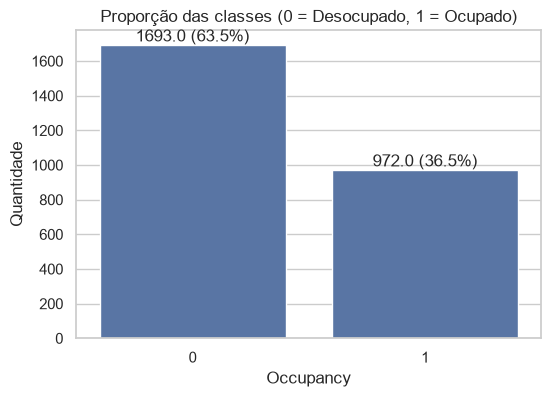

In [23]:
# Gráfico 1 — proporção das classes da variável alvo
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x=TARGET, data=df, ax=ax)
total = len(df)
for p in ax.patches:
    ax.annotate(f"{p.get_height()} ({p.get_height() / total:.1%})",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Proporção das classes (0 = Desocupado, 1 = Ocupado)")
ax.set_xlabel("Occupancy")
ax.set_ylabel("Quantidade")
plt.show()

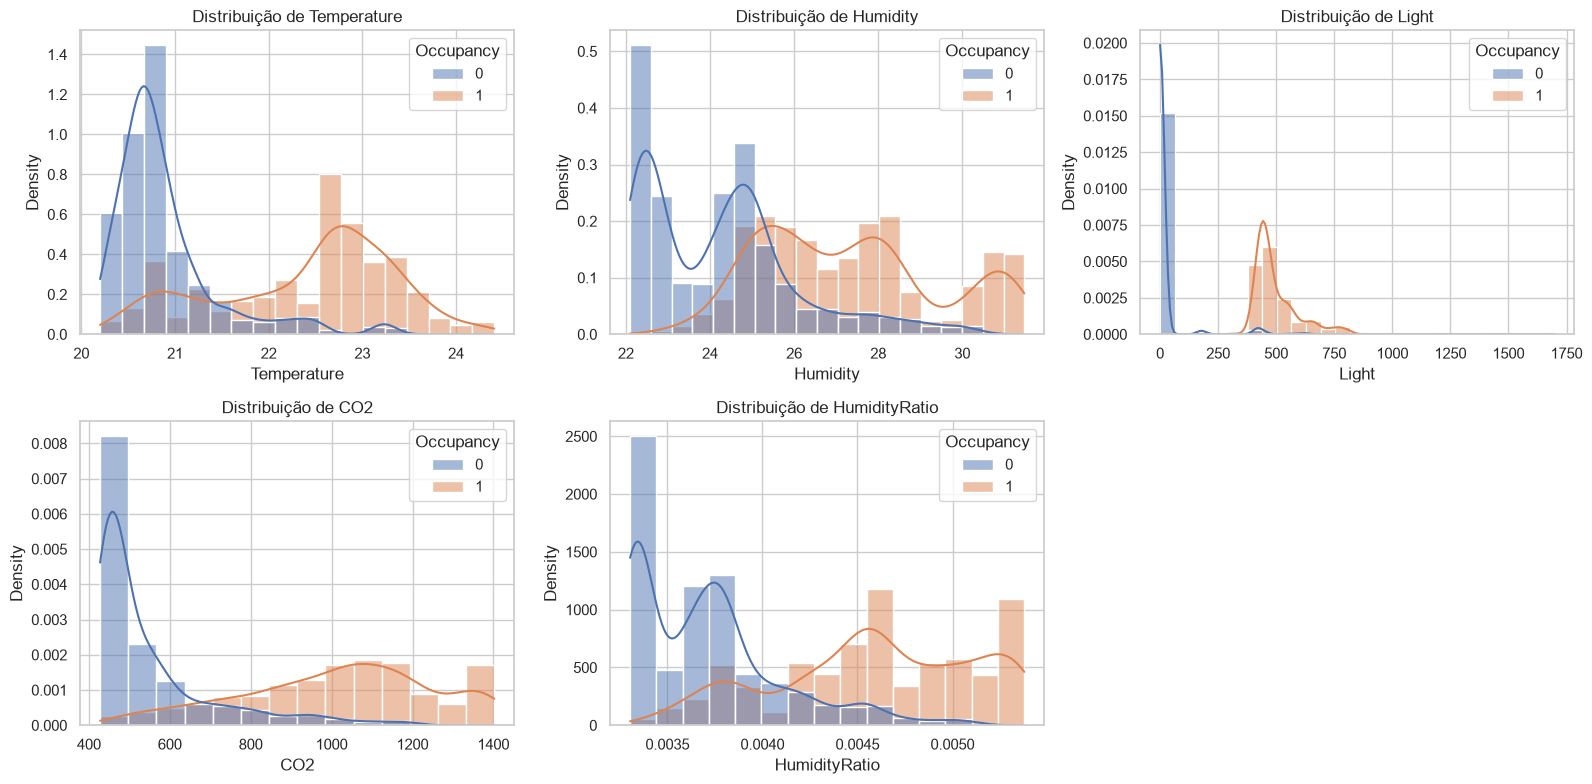

In [24]:
# Gráfico 2 — distribuição das variáveis preditoras, separada por classe
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, FEATURES):
    sns.histplot(data=df, x=col, hue=TARGET, kde=True, stat="density",
                 common_norm=False, ax=ax)
    ax.set_title(f"Distribuição de {col}")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

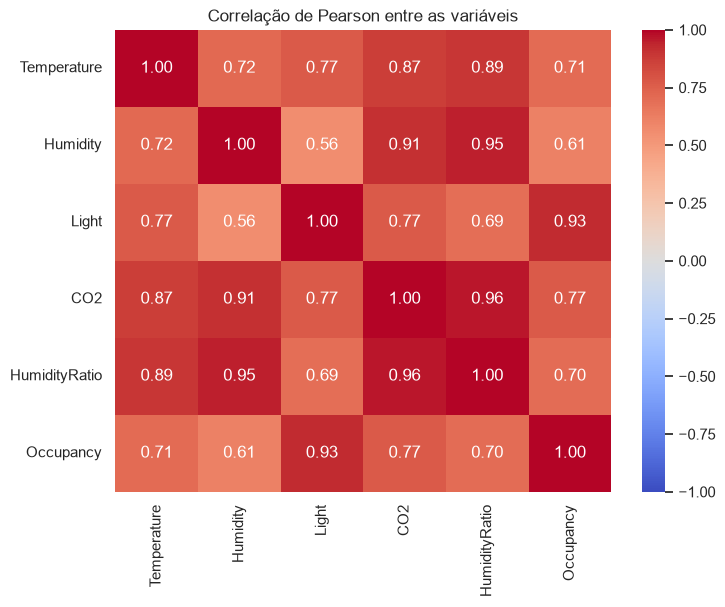

In [25]:
# Gráfico 3 — mapa de calor da correlação de Pearson
corr = df.drop(columns="date").corr(method="pearson")
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação de Pearson entre as variáveis")
plt.show()

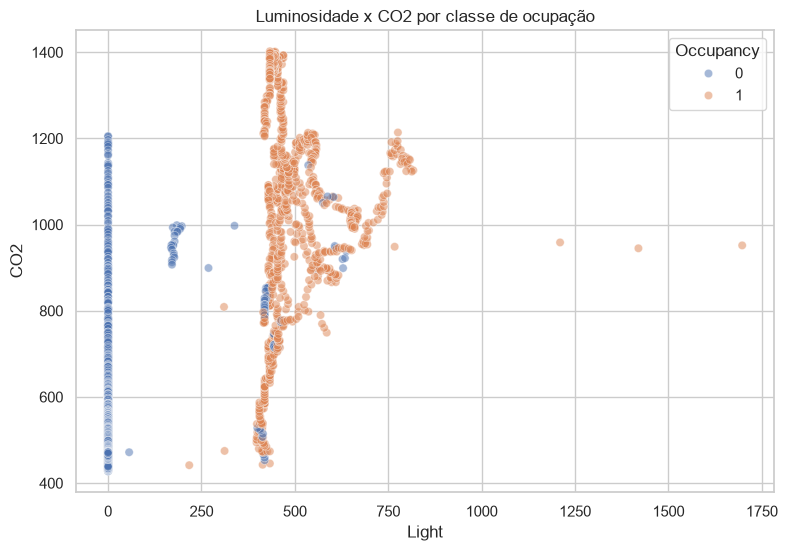

Correlação de cada variável com Occupancy:


,pearson
Light,0.927949
CO2,0.768030
Temperature,0.705784
HumidityRatio,0.700330
Humidity,0.610764


Média e mediana por classe:


Occupancy                   0         1
Temperature   mean     20.884    22.391
              median   20.700    22.680
Humidity      mean     24.226    27.318
              median   24.200    27.120
Light         mean     17.333   499.596
              median    0.000   461.000
CO2           mean    547.613  1014.518
              median  479.250  1038.250
HumidityRatio mean      0.004     0.005
              median    0.004     0.005

In [26]:
# Gráfico 4 — Luminosidade x CO2 colorido pela ocupação
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Light", y="CO2", hue=TARGET, alpha=0.5)
plt.title("Luminosidade x CO2 por classe de ocupação")
plt.show()

# Números que sustentam a análise textual
print("Correlação de cada variável com Occupancy:")
display(corr[TARGET].drop(TARGET).sort_values(ascending=False).to_frame("pearson"))
print("Média e mediana por classe:")
display(df.groupby(TARGET)[FEATURES].agg(["mean", "median"]).round(3).T)

### Análise dos gráficos e impacto na estratégia de modelagem

- **Classes levemente desbalanceadas:** a classe 1 (ocupado) é minoria, em torno de 36% contra 64% (Gráfico 1). Não é um desbalanceamento forte, mas justifica usar `stratify=y` na divisão treino/teste e olhar precisão, recall e F1 por classe na avaliação final, não só a acurácia.
- **Light (0,93) e CO2 (0,77) são os sinais mais fortes de ocupação:** têm as maiores correlações com `Occupancy` (tabela acima) e, no gráfico de dispersão, as duas classes ficam em regiões distintas: ambiente ocupado tem mais luz acesa e mais CO2 (respiração das pessoas). Isso indica que as duas variáveis darão a maior parte do poder de decisão dos modelos.
- **Temperature (0,71), HumidityRatio (0,70) e Humidity (0,61)** também têm correlação positiva moderada a forte com o alvo: com pessoas na sala, temperatura, umidade e CO2 sobem.
- **Forte multicolinearidade entre os sensores:** o mapa de calor mostra `HumidityRatio` com correlação de 0,96 com `CO2` e 0,95 com `Humidity`, e `Humidity` com `CO2` em 0,91. As variáveis carregam informação parecida (`HumidityRatio` é derivada de `Humidity` e `Temperature`). Isso não prejudica a Árvore, mas indica informação redundante.
- **Escalas muito diferentes:** `Light` vai de 0 a mais de 1000 lux, `CO2` fica na casa das centenas de ppm, `Temperature` varia poucos graus e `HumidityRatio` fica em ordem de milésimos. Isso exige `StandardScaler` no **KNN** (baseado em distância), enquanto a **Árvore** dispensa o escalonamento.
- **Distribuições assimétricas à direita** (histogramas): em `Light`, mais da metade das leituras é 0 (ambiente escuro) e `CO2` tem cauda à direita. Isso pesa na escolha entre média e mediana na imputação (Fase 2).

---
# Fase 2 — Limpeza e Tratamento de Dados (Data Prep)

## 2.1 Linhas duplicadas
A checagem usa todas as colunas, incluindo `date`: duas leituras idênticas no mesmo instante são duplicata real; leituras iguais em horários diferentes não são.

In [27]:
linhas_antes = len(df)
n_duplicadas = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicadas encontradas: {n_duplicadas}")
print(f"Linhas: {linhas_antes} -> {len(df)}")

# Agora sim descartamos 'date' (decisão justificada na Fase 1)
df = df.drop(columns="date")
print("Colunas após descartar 'date':", list(df.columns))

Duplicadas encontradas: 0
Linhas: 2665 -> 2665
Colunas após descartar 'date': ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio', 'Occupancy']


## 2.2 Dados ausentes (NaN)
Primeiro verificamos a base real. Se ela não tiver nulos (o caso da base da UCI), **simulamos** ausências em 3% das linhas de `Temperature`, `Light` e `CO2` com semente fixa, para validar que o pipeline de imputação funciona. O alvo `Occupancy` nunca é alterado.

In [28]:
print("Nulos na base original:")
print(df.isna().sum(), "\n")

if df.isna().sum().sum() == 0:
    rng = np.random.default_rng(RANDOM_STATE)
    for col in ["Temperature", "Light", "CO2"]:
        idx = rng.choice(df.index, size=int(0.03 * len(df)), replace=False)
        df.loc[idx, col] = np.nan
    print("Nulos simulados para validação do pipeline:")
    print(df.isna().sum())

Nulos na base original:
Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
dtype: int64 

Nulos simulados para validação do pipeline:
Temperature      79
Humidity          0
Light            79
CO2              79
HumidityRatio     0
Occupancy         0
dtype: int64


In [29]:
# Evidências para escolher média ou mediana: assimetria e distância média x mediana
diagnostico = pd.DataFrame({
    "assimetria (skew)": df[FEATURES].skew(),
    "media": df[FEATURES].mean(),
    "mediana": df[FEATURES].median(),
})
# Distância entre média e mediana em desvios-padrão (funciona mesmo quando a mediana é 0)
diagnostico["(media - mediana) / desvio"] = (
    (diagnostico["media"] - diagnostico["mediana"]) / df[FEATURES].std()
)
display(diagnostico.round(4))

,assimetria (skew),media,mediana,(media - mediana) / desvio
Temperature,0.8385,21.4366,20.8900,0.5296
Humidity,0.6728,25.3539,25.0000,0.1452
Light,0.7619,193.5830,0.0000,0.7730
CO2,0.7783,719.7048,582.0250,0.4693
HumidityRatio,0.6494,0.0040,0.0038,0.3471


### Justificativa: imputação pela **mediana**
A média é puxada por valores extremos; a mediana não. A tabela acima mostra assimetria positiva nas cinco variáveis (entre 0,65 e 0,84), então a média fica acima da mediana. O efeito é mais evidente em `Light`, onde mais da metade das leituras é 0 (mediana 0, média de cerca de 194 lux), e em `CO2` (média de cerca de 720 ppm contra mediana de cerca de 582 ppm). Imputar `Light` pela média colocaria um valor de ~194 lux, que fica longe do valor típico de cada grupo (mediana de 0 lux nos ambientes vazios e de 461 lux nos ocupados, conforme a tabela da Fase 1); a mediana preserva o valor típico da distribuição. Para manter **uma regra única e simples** em todas as colunas, usamos a mediana em todas as variáveis numéricas, inclusive nas mais simétricas, onde o resultado é praticamente igual ao da média.

**Efeito colateral a considerar:** a maioria das leituras é de ambiente vazio e escuro, então a mediana de `Light` é exatamente 0 (valor impresso acima). Como os nulos simulados sorteiam linhas de qualquer classe, cerca de 3% das linhas "ocupadas" perdem o `Light` e passam a parecer "no escuro". Isso é ruído injetado de propósito e as acurácias finais já refletem esse efeito. Em uma base real com nulos, valeria avaliar alternativas (por exemplo, imputação por modelo ou por vizinhos).

In [30]:
medianas = df[FEATURES].median()
print(f"Mediana usada para imputar Light: {medianas['Light']:.2f} | CO2: {medianas['CO2']:.2f}")

df[FEATURES] = df[FEATURES].fillna(medianas)

print("\nNulos após imputação pela mediana:")
print(df.isna().sum())
assert df.isna().sum().sum() == 0

Mediana usada para imputar Light: 0.00 | CO2: 582.02

Nulos após imputação pela mediana:
Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
dtype: int64


## 2.3 Outliers (boxplots)
Um boxplot por variável, cada um com sua escala, pois as unidades são muito diferentes.

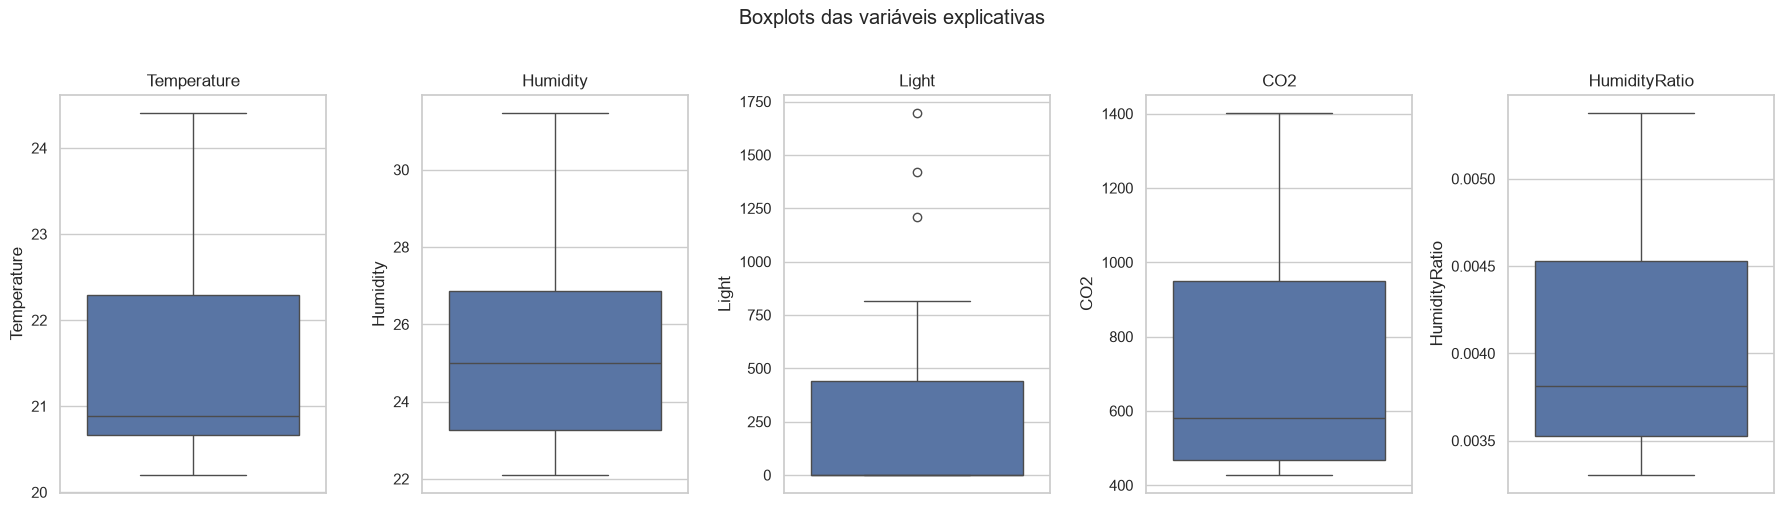

Light: classe (Occupancy) dos outliers -> {1: 3}


,outliers,% da base
Temperature,0.0,0.00
Humidity,0.0,0.00
Light,3.0,0.11
CO2,0.0,0.00
HumidityRatio,0.0,0.00


In [31]:
fig, axes = plt.subplots(1, 5, figsize=(18, 5))
for ax, col in zip(axes, FEATURES):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Boxplots das variáveis explicativas", y=1.02)
plt.tight_layout()
plt.show()

# Contagem de outliers pela regra do IQR (1,5 x IQR)
resumo = {}
for col in FEATURES:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    resumo[col] = {"outliers": int(mask.sum()), "% da base": round(100 * mask.mean(), 2)}
    if mask.any():
        print(f"{col}: classe (Occupancy) dos outliers -> {df.loc[mask, TARGET].value_counts().to_dict()}")
display(pd.DataFrame(resumo).T)

### Decisão sobre os outliers: **mantidos**
A contagem pelo IQR mostra **pouquíssimos outliers**: em `Light` são apenas 3 leituras (0,11% da base) e em `CO2` nenhuma (as demais variáveis não têm nenhum). As 3 leituras são de ambiente ocupado (`Occupancy = 1`), coerente com iluminação muito acesa. Com tão poucos pontos, não há evidência de erro sistemático de sensor, e remover 3 linhas mudaria quase nada nos resultados. Valores altos de `Light` são plausíveis (iluminação acesa), então descartá-los seria perder informação real sem ganho. Além disso, a Árvore de Decisão é robusta a valores extremos e o KNN receberá dados escalonados, o que limita a influência desses pontos.

---
# Fase 3 — Feature Engineering

Criamos a variável **`razao_co2_luz = CO2 / (Light + 1)`**, que relaciona os dois sinais mais fortes de ocupação identificados na EDA. O `+ 1` evita divisão por zero quando o ambiente está no escuro (`Light = 0`). Antes do cálculo, confirmamos que não há nulos.

In [32]:
# Garantia de que não há nulos antes do cálculo
assert df[["CO2", "Light"]].isna().sum().sum() == 0

df["razao_co2_luz"] = df["CO2"] / (df["Light"] + 1)

# Validação: sem NaN e sem infinitos
assert df["razao_co2_luz"].notna().all()
assert np.isfinite(df["razao_co2_luz"]).all()

print("Nova coluna criada: razao_co2_luz")
display(df["razao_co2_luz"].describe().to_frame().T)
display(df.groupby(TARGET)["razao_co2_luz"].agg(["mean", "median"]).round(3))

Nova coluna criada: razao_co2_luz


,count,mean,std,min,25%,50%,75%,max
razao_co2_luz,2665.0,336.605377,289.529895,0.56043,2.254503,443.0,511.8,1394.6


,mean,median
Occupancy,,
0,512.125,474.000
1,30.890,2.009


**Leitura do resultado:** a razão separa bem as classes. Em ambiente ocupado ela é baixa (mediana 2,0), porque a luz está acesa e `Light` é alto; em ambiente vazio é alta (mediana 474), porque `Light` é perto de zero e o CO2 permanece em centenas de ppm. Como `Light` domina o denominador, a variável funciona em boa parte como um indicador de luz acesa/apagada ajustado pelo CO2.

A nova coluna passa a ser mais uma variável preditora (`FEATURES_MODEL`), usada pelos dois modelos. Como a escala dela é diferente das demais, ela também será padronizada no KNN.

---
# Fase 4 — Divisão e Balanceamento dos Dados

Separamos preditoras (`X`) e alvo (`y`) e dividimos em **80% treino / 20% teste**, com `stratify=y` (mantém a proporção das classes nos dois conjuntos) e `random_state=42` (mesma divisão em toda execução).

In [33]:
FEATURES_MODEL = FEATURES + ["razao_co2_luz"]
X = df[FEATURES_MODEL]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Treino: {X_train.shape} | Teste: {X_test.shape}\n")
proporcoes = pd.DataFrame({
    "base completa": y.value_counts(normalize=True),
    "treino": y_train.value_counts(normalize=True),
    "teste": y_test.value_counts(normalize=True),
}).round(4)
display(proporcoes)

Treino: (2132, 6) | Teste: (533, 6)



,base completa,treino,teste
Occupancy,,,
0,0.6353,0.6351,0.636
1,0.3647,0.3649,0.364


### Por que dividir **antes** de qualquer transformação de escala (Data Leakage)
O `StandardScaler` calcula média e desvio-padrão. Se esses valores fossem calculados com a base inteira, o conjunto de teste participaria da preparação dos dados de treino: informação do "futuro" vazaria para o modelo, e o teste deixaria de simular dados nunca vistos. O resultado seria uma acurácia **otimista**, que não se repetiria em produção.

Por isso a ordem é: **dividir → ajustar (`fit`) o scaler só no treino → aplicar (`transform`) no teste** com os parâmetros aprendidos no treino. A estratificação garante que a proporção das classes seja a mesma nos dois conjuntos, tornando a comparação entre treino e teste justa.

---
# Fase 5 — Escalonamento de Variáveis (StandardScaler)

- **KNN:** recebe dados padronizados (`StandardScaler`), com `fit_transform` **apenas no treino** e `transform` no teste.
- **Árvore de Decisão:** recebe os dados **originais**, sem escalonamento.

In [34]:
scaler = StandardScaler()

# KNN: fit_transform SÓ no treino; no teste apenas transform (usa média/desvio do treino)
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train),
                              columns=FEATURES_MODEL, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test),
                             columns=FEATURES_MODEL, index=X_test.index)

# Árvore de Decisão: usa X_train / X_test ORIGINAIS (sem escalonamento).
# Árvores decidem por cortes do tipo "Light <= valor", comparando a ordem dos valores
# de UMA variável por vez. A padronização é uma transformação monotônica (preserva a
# ordem), então produz os mesmos cortes e o mesmo ganho de informação: a diferença de
# escala entre Lux (0 a >1000) e Temperatura (19 a 24) é irrelevante para a Árvore.

print("Média e desvio no treino escalonado (esperado: ~0 e ~1):")
display(X_train_scaled.agg(["mean", "std"]).round(3))
print("Mesmas estatísticas no teste escalonado (próximas, mas não exatamente 0 e 1):")
display(X_test_scaled.agg(["mean", "std"]).round(3))

Média e desvio no treino escalonado (esperado: ~0 e ~1):


,Temperature,Humidity,Light,CO2,HumidityRatio,razao_co2_luz
mean,0.0,0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


Mesmas estatísticas no teste escalonado (próximas, mas não exatamente 0 e 1):


,Temperature,Humidity,Light,CO2,HumidityRatio,razao_co2_luz
mean,0.031,0.036,-0.005,0.010,0.036,0.006
std,1.059,1.009,1.004,1.033,1.024,1.003


### Por que escalonar só o KNN
O **KNN** classifica pela distância euclidiana entre pontos. Sem padronização, `Light` (centenas de lux) e `CO2` (centenas de ppm) dominariam o cálculo, e `Temperature` e `HumidityRatio` seriam praticamente ignoradas só pela escala. A padronização coloca todas as variáveis com média 0 e desvio 1 e dá a elas pesos comparáveis.

A **Árvore** é imune a esse problema, como explicado no comentário do código. Aplicar o escalonamento nela não muda o resultado, só adiciona uma etapa e dificulta a interpretação dos cortes (valores em lux viram desvios-padrão).

O teste foi escalonado com `transform` (não `fit_transform`), usando a média e o desvio **do treino**, o que evita Data Leakage.

---
# Fase 6 — Ajuste de Parâmetros e Combate ao Overfitting

Treinamos cada modelo com vários valores do hiperparâmetro principal e registramos a acurácia no **treino** e no **teste**.

**Critério de diagnóstico** (o teste tem cerca de 533 amostras, então 1 ponto percentual equivale a ~5 amostras; diferenças menores que isso são ruído):
- **Overfitting:** acurácia de treino alta com diferença treino − teste ≥ 1 p.p. (queda no teste).
- **Subajuste:** sem overfitting, mas com acurácia de teste mais de 1 p.p. abaixo da melhor configuração do mesmo modelo (modelo simples demais).
- **ok:** nenhum dos dois.

- **KNN:** `n_neighbors` (K) ímpar: 1, 3, 5, 7, 9, 15, 21.
- **Árvore:** `max_depth`: 1, 2, 3, 5, 10 e `None` (sem limite).

In [35]:
valores_k = [1, 3, 5, 7, 9, 15, 21]
profundidades = [1, 2, 3, 5, 10, None]
LIMIAR_GAP = 0.01  # 1 p.p. (~5 amostras em 533): abaixo disso a diferença é ruído

# ---- KNN (dados escalonados)
modelos_knn, linhas = {}, []
for k in valores_k:
    modelo = KNeighborsClassifier(n_neighbors=k).fit(X_train_scaled, y_train)
    modelos_knn[k] = modelo
    linhas.append({
        "K": k,
        "acc_treino": accuracy_score(y_train, modelo.predict(X_train_scaled)),
        "acc_teste": accuracy_score(y_test, modelo.predict(X_test_scaled)),
    })
res_knn = pd.DataFrame(linhas)

# ---- Árvore de Decisão (dados SEM escalonamento)
modelos_arv, linhas = {}, []
for d in profundidades:
    modelo = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    rotulo = "None" if d is None else d
    modelos_arv[rotulo] = modelo
    linhas.append({
        "max_depth": rotulo,
        "acc_treino": accuracy_score(y_train, modelo.predict(X_train)),
        "acc_teste": accuracy_score(y_test, modelo.predict(X_test)),
    })
res_arv = pd.DataFrame(linhas)

def diagnosticar(res):
    melhor_teste = res["acc_teste"].max()
    def rotulo(r):
        if r["gap (treino - teste)"] >= LIMIAR_GAP:
            return "overfitting"
        if r["acc_teste"] < melhor_teste - LIMIAR_GAP:
            return "subajuste"
        return "ok"
    return res.apply(rotulo, axis=1)

def escolher_melhor(res):
    """Maior acurácia no teste; empate -> menor gap treino-teste."""
    return res.sort_values(["acc_teste", "gap (treino - teste)"],
                           ascending=[False, True]).iloc[0]

for res in (res_knn, res_arv):
    res["gap (treino - teste)"] = res["acc_treino"] - res["acc_teste"]
    res["diagnostico"] = diagnosticar(res)

print("KNN — acurácia por valor de K")
display(res_knn.round(4))
print("Árvore de Decisão — acurácia por max_depth")
display(res_arv.round(4))

KNN — acurácia por valor de K


,K,acc_treino,acc_teste,gap (treino - teste),diagnostico
0,1,1.0000,0.9831,0.0169,overfitting
1,3,0.9916,0.9794,0.0122,overfitting
2,5,0.9892,0.9756,0.0136,overfitting
3,7,0.9826,0.9737,0.0089,ok
4,9,0.9808,0.9756,0.0052,ok
5,15,0.9709,0.9644,0.0066,subajuste
6,21,0.9705,0.9625,0.0080,subajuste


Árvore de Decisão — acurácia por max_depth


,max_depth,acc_treino,acc_teste,gap (treino - teste),diagnostico
0,1,0.9705,0.9644,0.0061,subajuste
1,2,0.9705,0.9644,0.0061,subajuste
2,3,0.9756,0.9719,0.0038,subajuste
3,5,0.9883,0.9812,0.0070,ok
4,10,0.9995,0.9887,0.0108,overfitting
5,None,1.0000,0.9887,0.0113,overfitting


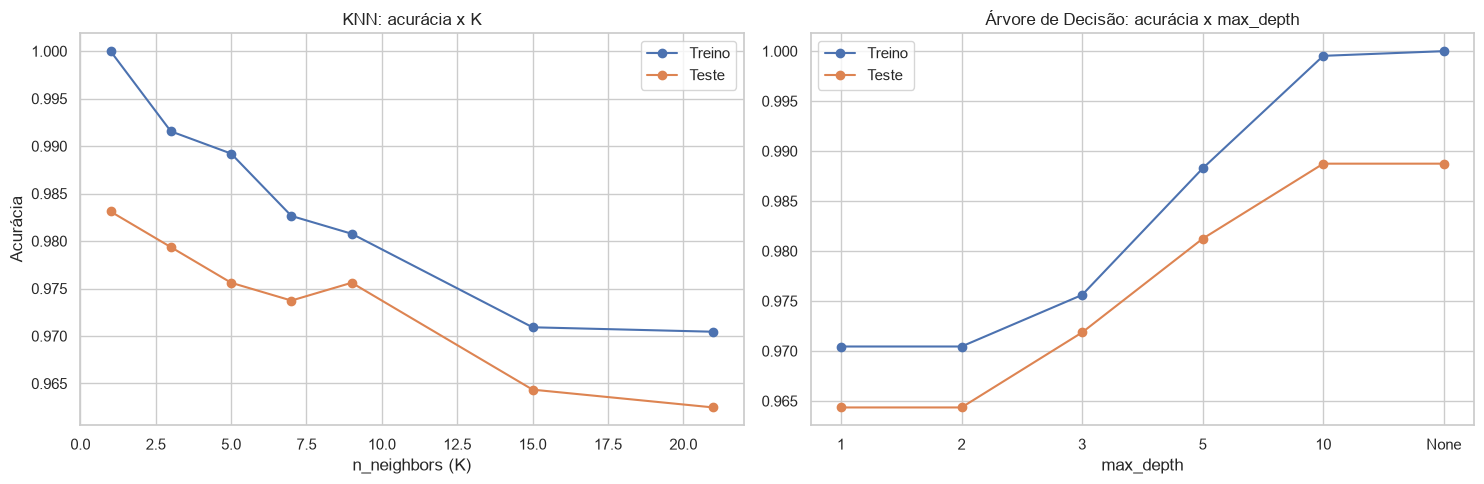


KNN
  overfitting : [1, 3, 5]
  subajuste   : [15, 21]
  ok          : [7, 9]
  menor gap   : K = 9 (gap 0.0052, acc teste 0.9756)
  maior acc teste: K = 1 (acc teste 0.9831, gap 0.0169)

Árvore
  overfitting : [10, 'None']
  subajuste   : [1, 2, 3]
  ok          : [5]
  menor gap   : max_depth = 3 (gap 0.0038, acc teste 0.9719)
  maior acc teste: max_depth = 10 (acc teste 0.9887, gap 0.0108)


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(res_knn["K"], res_knn["acc_treino"], marker="o", label="Treino")
axes[0].plot(res_knn["K"], res_knn["acc_teste"], marker="o", label="Teste")
axes[0].set_title("KNN: acurácia x K")
axes[0].set_xlabel("n_neighbors (K)")
axes[0].set_ylabel("Acurácia")
axes[0].legend()

x_arv = res_arv["max_depth"].astype(str)
axes[1].plot(x_arv, res_arv["acc_treino"], marker="o", label="Treino")
axes[1].plot(x_arv, res_arv["acc_teste"], marker="o", label="Teste")
axes[1].set_title("Árvore de Decisão: acurácia x max_depth")
axes[1].set_xlabel("max_depth")
axes[1].legend()

plt.tight_layout()
plt.show()

# Diagnóstico automático (números reais das tabelas)
for nome, res, col in [("KNN", res_knn, "K"), ("Árvore", res_arv, "max_depth")]:
    print(f"\n{nome}")
    for rot in ["overfitting", "subajuste", "ok"]:
        vals = res.loc[res["diagnostico"] == rot, col].tolist()
        print(f"  {rot:12s}: {vals if vals else 'nenhuma'}")
    menor = res.loc[res["gap (treino - teste)"].idxmin()]
    melhor = escolher_melhor(res)
    print(f"  menor gap   : {col} = {menor[col]} (gap {menor['gap (treino - teste)']:.4f}, "
          f"acc teste {menor['acc_teste']:.4f})")
    print(f"  maior acc teste: {col} = {melhor[col]} (acc teste {melhor['acc_teste']:.4f}, "
          f"gap {melhor['gap (treino - teste)']:.4f})")

### Análise de overfitting e estabilidade

**KNN**
- **Overfitting em K = 1, 3 e 5:** a diferença treino-teste é de 1,69 p.p. (K = 1: treino 100% contra teste 98,31%), 1,22 p.p. (K = 3) e 1,36 p.p. (K = 5). Com K = 1 cada ponto de treino é o próprio vizinho mais próximo, então o treino é perfeito por construção.
- **K = 7 e 9 são as mais estáveis:** diagnóstico "ok", e K = 9 tem o menor gap do KNN (0,52 p.p.), com 97,56% no teste.
- **Subajuste em K = 15 e 21:** o teste cai para 96,44% e 96,25%. Votar entre muitos vizinhos suaviza demais a fronteira entre as classes. Ou seja, aumentar K reduz o gap, mas só até certo ponto: depois disso a acurácia piora, e a melhor acurácia de teste do KNN continua em K = 1 (98,31%).

**Árvore de Decisão**
- **Overfitting em `max_depth` = 10 e `None`:** treino de 99,95% e 100% contra 98,87% no teste nas duas, gap de cerca de 1,1 p.p. As duas empatam em acurácia de teste (98,87%); a de profundidade 10 é a escolhida por ter o menor gap.
- **`max_depth` = 5 é a mais equilibrada:** diagnóstico "ok", gap de 0,70 p.p. e 98,12% no teste.
- **Subajuste em `max_depth` = 1, 2 e 3:** a acurácia de teste fica em 96,44% (profundidades 1 e 2) e 97,19% (profundidade 3). A profundidade 3 tem o menor gap da Árvore (0,38 p.p.), mas só porque o modelo é simples demais e erra também no treino.

**Escolha dos modelos finais:** o roteiro pede o melhor modelo pela acurácia de teste, e por esse critério ficam **KNN com K = 1** e **Árvore com `max_depth = 10`**. As duas configurações foram classificadas como *overfitting* pelo critério acima, e a escolha tem ressalvas: (1) as alternativas mais estáveis (KNN com K = 9; Árvore com `max_depth = 5`) perdem apenas alguns acertos no teste; (2) o conjunto de teste foi usado tanto para escolher quanto para avaliar; (3) a divisão aleatória de uma série temporal coloca leituras de minutos vizinhos (quase idênticas) em treino e teste, o que favorece especialmente o KNN com K = 1 (ver Limitações).

---
# Fase 7 — Avaliação da Acurácia e Veredito Final

Escolhemos o melhor KNN e a melhor Árvore e avaliamos **exclusivamente no conjunto de teste**. Critério: maior `acc_teste`; em caso de empate, menor gap treino-teste.

In [37]:
melhor_k = int(escolher_melhor(res_knn)["K"])
melhor_d = escolher_melhor(res_arv)["max_depth"]

knn_final = modelos_knn[melhor_k]
arv_final = modelos_arv[melhor_d]

y_pred_knn = knn_final.predict(X_test_scaled)   # KNN: teste escalonado
y_pred_arv = arv_final.predict(X_test)          # Árvore: teste original

acc_knn = accuracy_score(y_test, y_pred_knn)
acc_arv = accuracy_score(y_test, y_pred_arv)

print(f"Melhor KNN   : K = {melhor_k}  -> acurácia no teste = {acc_knn:.4f}")
print(f"Melhor Árvore: max_depth = {melhor_d}  -> acurácia no teste = {acc_arv:.4f}\n")

print("=== KNN ===")
print(classification_report(y_test, y_pred_knn, target_names=["Desocupado", "Ocupado"], digits=4))
print("=== Árvore de Decisão ===")
print(classification_report(y_test, y_pred_arv, target_names=["Desocupado", "Ocupado"], digits=4))

Melhor KNN   : K = 1  -> acurácia no teste = 0.9831
Melhor Árvore: max_depth = 10  -> acurácia no teste = 0.9887

=== KNN ===
              precision    recall  f1-score   support

  Desocupado     0.9853    0.9882    0.9867       339
     Ocupado     0.9793    0.9742    0.9767       194

    accuracy                         0.9831       533
   macro avg     0.9823    0.9812    0.9817       533
weighted avg     0.9831    0.9831    0.9831       533

=== Árvore de Decisão ===
              precision    recall  f1-score   support

  Desocupado     0.9912    0.9912    0.9912       339
     Ocupado     0.9845    0.9845    0.9845       194

    accuracy                         0.9887       533
   macro avg     0.9878    0.9878    0.9878       533
weighted avg     0.9887    0.9887    0.9887       533



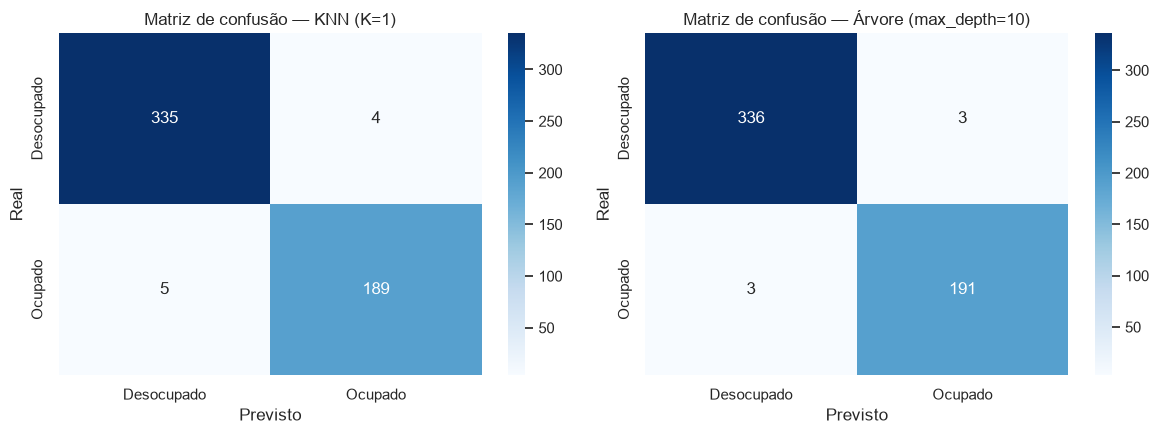

,Acurácia no teste,Precisa de escalonamento
Modelo,,
KNN (K=1),0.9831,Sim
Árvore (max_depth=10),0.9887,Não


Diferença: 0.56 p.p. (~3 amostras em 533)
Diferença dentro do ruído (<= 1 p.p.): praticamente empate. Recomenda-se a ÁRVORE DE DECISÃO pelos critérios operacionais (sem escalonamento, inferência mais rápida, interpretável).


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, y_pred, titulo in [(axes[0], y_pred_knn, f"KNN (K={melhor_k})"),
                           (axes[1], y_pred_arv, f"Árvore (max_depth={melhor_d})")]:
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=["Desocupado", "Ocupado"],
                yticklabels=["Desocupado", "Ocupado"], ax=ax)
    ax.set_title(f"Matriz de confusão — {titulo}")
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

comparativo = pd.DataFrame({
    "Modelo": [f"KNN (K={melhor_k})", f"Árvore (max_depth={melhor_d})"],
    "Acurácia no teste": [acc_knn, acc_arv],
    "Precisa de escalonamento": ["Sim", "Não"],
}).set_index("Modelo")
display(comparativo.round(4))

# Veredito
dif = acc_arv - acc_knn
n_dif = round(abs(dif) * len(y_test))
print(f"Diferença: {abs(dif) * 100:.2f} p.p. (~{n_dif} amostras em {len(y_test)})")
if abs(dif) <= 0.01:
    print("Diferença dentro do ruído (<= 1 p.p.): praticamente empate. "
          "Recomenda-se a ÁRVORE DE DECISÃO pelos critérios operacionais "
          "(sem escalonamento, inferência mais rápida, interpretável).")
elif dif > 0:
    print("A Árvore de Decisão supera o KNN em acurácia no teste.")
else:
    print("O KNN supera a Árvore em acurácia no teste.")

## Conclusão técnica

**Modelo escolhido para o sistema de automação predial: Árvore de Decisão com `max_depth = 10`, com 98,87% de acurácia no conjunto de teste.** O melhor KNN (K = 1) obteve 98,31%. A diferença é de 0,56 ponto percentual, ou cerca de 3 acertos a mais em 533 amostras, o que é praticamente um empate técnico. Todos os valores foram medidos no conjunto de teste, que nenhum modelo usou para treinar. As ressalvas sobre a imputação (feita na base inteira) e sobre a escolha dos hiperparâmetros (feita olhando o teste) estão listadas logo abaixo.

**Por que a Árvore, mesmo com a diferença pequena:**
1. Teve a maior acurácia no teste, que é o critério pedido no roteiro, e foi melhor nas duas classes. No recall da classe "Ocupado", que é a que mais importa (evitar desligar o ar-condicionado com pessoas na sala), a Árvore obteve 98,45% contra 97,42% do KNN.
2. Não precisa de escalonamento, a predição é rápida (poucas comparações de corte) e o KNN precisa guardar toda a base de treino e calcular distâncias a cada leitura, o que pesa em dispositivos de borda (edge).
3. É interpretável: as regras (cortes em `Light` e `CO2`, por exemplo) podem ser auditadas pela equipe de manutenção.

**Ressalvas sobre a escolha:** os dois modelos escolhidos (K = 1 e `max_depth = 10`) foram classificados como *overfitting* na Fase 6 (gaps de 1,69 e 1,08 p.p.) e foram selecionados olhando o próprio conjunto de teste, o que torna a acurácia levemente otimista. Se a prioridade for estabilidade, a Árvore com `max_depth = 5` (98,12% no teste, gap de 0,70 p.p.) perde apenas cerca de 4 acertos em 533 e é uma alternativa mais conservadora. No KNN, K = 9 (97,56%, gap de 0,52 p.p.) cumpre esse papel. As classes são levemente desbalanceadas (cerca de 64% x 36%), por isso a acurácia sozinha não basta e o recall por classe também foi avaliado.

## Limitações e melhorias possíveis
- **Divisão aleatória em série temporal:** leituras de minutos vizinhos são quase idênticas e podem cair uma no treino e outra no teste. Isso ajuda o KNN com K = 1 a ir tão bem e pode inflar a acurácia. Testar com `datatraining.txt` e `datatest2.txt` (períodos diferentes) mediria melhor a generalização no tempo.
- A imputação (Fase 2) usou a base inteira, por exigência da ordem do roteiro, e os nulos foram simulados. Em produção, o ideal é `SimpleImputer` dentro de um `Pipeline` do scikit-learn, ajustado só no treino.
- Os hiperparâmetros foram comparados no próprio conjunto de teste. O ideal é escolhê-los com validação cruzada (`GridSearchCV`) e usar o teste apenas uma vez no final.
- Variáveis derivadas do horário (hora do dia, dia útil) poderiam melhorar a previsão, mas exigem uma estratégia de divisão temporal.